<a href="https://colab.research.google.com/github/riasharma0902/BMEN-600-Project/blob/main/preliminary_results.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

METADATA_TSV = Path("/content/drive/MyDrive/BraTS-PEDs_metadata.tsv")
OUT_DIR = Path("/content/drive/MyDrive/BMEN600_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

ID_COL, SURV_COL, SPLIT_COL = "BraTS-SubjectID", "Overall survival (days)", "BraTS2025_cohort"

print("metadata exists:", METADATA_TSV.exists(), "| image dir exists:", IMAGE_DIR.exists())

Mounted at /content/drive
metadata exists: True | image dir exists: True


In [ ]:
meta = pd.read_csv(METADATA_TSV, sep="\t")
df = meta.copy()
df["subject"] = df[ID_COL].str.extract(r"(\d{5})")[0]
assert df["subject"].notna().all() and df["subject"].is_unique

# Survival: anything non-numeric becomes missing, but show what those entries are
df["os_days"] = pd.to_numeric(df[SURV_COL], errors="coerce")
df["has_survival"] = df["os_days"].notna()

print("Rows:", len(df))
print("\nChallenge cohorts:\n", df[SPLIT_COL].value_counts(dropna=False))
print("\nSurvival recorded:", df["has_survival"].sum(), "| missing:", (~df["has_survival"]).sum())
print("\nNon-numeric survival entries:\n", df.loc[~df["has_survival"], SURV_COL].value_counts(dropna=False))

Rows: 457

Challenge cohorts:
 BraTS2025_cohort
Training      257
Test          109
Validation     91
Name: count, dtype: int64

Survival recorded: 115 | missing: 342

Non-numeric survival entries:
 Overall survival (days)
NaN             341
Not Reported      1
Name: count, dtype: int64


In [ ]:
# TCIA distributes images for Training + Validation only; Testing is hidden
split = df[SPLIT_COL].astype(str).str.lower()
df["images_distributed"] = split.str.startswith(("train", "val"))

print(pd.crosstab(df[SPLIT_COL], df["has_survival"], margins=True))

df["usable_est"] = df["has_survival"] & df["images_distributed"]
print("\nEstimated analysable cohort (survival recorded AND images distributed):", df["usable_est"].sum())
print(pd.crosstab(df.loc[df["usable_est"], SPLIT_COL], "n"))

has_survival      False  True  All
BraTS2025_cohort                  
Test                109     0  109
Training            142   115  257
Validation           91     0   91
All                 342   115  457

Estimated analysable cohort (survival recorded AND images distributed): 115
col_0               n
BraTS2025_cohort     
Training          115


In [ ]:
u = df[df["usable_est"]].copy()
u["age_years"] = u["Age at imaging (days)"] / 365.25

print("Overall survival (days):")
print(u["os_days"].describe())
print("\nAge at imaging (years):")
print(u["age_years"].describe())
print("\nSex:\n", u["Sex_at_birth"].value_counts(dropna=False))
print("\nSource:\n", u["Source"].value_counts(dropna=False))
print("\nOrganization:\n", u["Organization"].value_counts(dropna=False))
print("\nRace (all 457):\n", df["Race"].value_counts(dropna=False))
print("\nEthnicity (all 457):\n", df["Ethnicity"].value_counts(dropna=False))

Overall survival (days):
count     115.000000
mean      641.234783
std       788.584389
min        10.000000
25%       241.000000
50%       397.000000
75%       626.500000
max      5274.000000
Name: os_days, dtype: float64

Age at imaging (years):
count    115.000000
mean       9.544148
std        4.786276
min        0.418891
25%        5.987680
50%        8.208077
75%       12.505133
max       25.889117
Name: age_years, dtype: float64

Sex:
 Sex_at_birth
Female    64
Male      51
Name: count, dtype: int64

Source:
 Source
CBTN    115
Name: count, dtype: int64

Organization:
 Organization
The Children's Hospital of Philadelphia      74
Children's National Hospital (CNH)           36
Lurie Children's Hospital                     3
Children's National Medical Center (CNMC)     1
Dayton Children's Hospital                    1
Name: count, dtype: int64

Race (all 457):
 Race
NaN                                          341
White                                         71
Black or African 

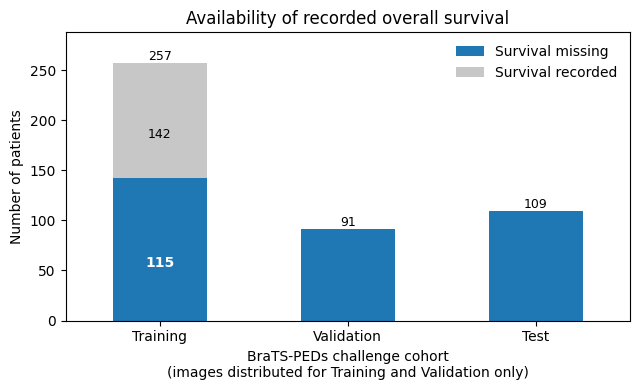

In [ ]:
# Figure 1: survival availability by challenge cohort
# First define counts by calculating the crosstab
counts = pd.crosstab(df[SPLIT_COL], df["has_survival"])
# Rename the columns from boolean to descriptive labels for plotting
counts = counts.rename(columns={True: "Survival recorded", False: "Survival missing"})

order = ["Training", "Validation", "Test"]
counts = counts.loc[order]

fig, ax = plt.subplots(figsize=(6.5, 4))
counts.plot(kind="bar", stacked=True, ax=ax, color=["#1f77b4", "#c7c7c7"], rot=0)

for i, (_, r) in enumerate(counts.iterrows()):
    ax.text(i, r.sum() + 3, int(r.sum()), ha="center", fontsize=9)
    if r["Survival recorded"] > 0:
        ax.text(i, r["Survival recorded"] / 2, int(r["Survival recorded"]),
                ha="center", va="center", color="white", fontsize=10, fontweight="bold")
        ax.text(i, r["Survival recorded"] + r["Survival missing"] / 2, int(r["Survival missing"]),
                ha="center", va="center", fontsize=9)

ax.set_xlabel("BraTS-PEDs challenge cohort\n(images distributed for Training and Validation only)")
ax.set_ylabel("Number of patients")
ax.set_title("Availability of recorded overall survival")
ax.legend(frameon=False)
ax.set_ylim(0, counts.sum(axis=1).max() * 1.12)
plt.tight_layout()
fig.savefig(OUT_DIR / "fig1_survival_availability.png", dpi=300)
plt.show()